In [1]:
import json
import pickle
from datetime import datetime
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay, accuracy_score,
    average_precision_score, classification_report, confusion_matrix, f1_score,
    precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "src" / "clases_po").exists():
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT / "src"))
from clases_po import HFDatasetLoader

OBJETIVO = "default.payment.next.month"
COLORES = {"paga": "#1f6fe5", "incumple": "#e5384b", "naranja": "#f2661b", "verde": "#10a179", "morado": "#8a3ff0"}
SEMILLA = 42
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 30)

c:\Users\user\Documents\Disco duro\Univerisidad\Machine Learning\ML_202604_Santiago_Lopez_F\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Etapa 1 * Extraccion -> escena 2

todos los avisos de arriendos en colombia 

In [3]:
hfdataset= HFDatasetLoader(dataset_name="aptologia/precios-arriendo-colombia", split="train", filename="datos/precios-arriendo-colombia_clasificacion.csv")

df_arriendo_crudo = hfdataset.load() #1 . Cargar

print ("Forma (filas, columnas()", df_arriendo_crudo.shape)
df_arriendo_crudo.head()

Forma (filas, columnas() (1460, 10)


,fecha,ciudad_id,ciudad,barrio,avisos,p25,mediana,p75,con_parqueadero,con_telefono
0,2026-10-05,medellin,Medellín,El Poblado,17124,4400000,5700000,7700000,15907,6599
1,2026-10-05,medellin,Medellín,Poblado,7593,4100000,5650000,8000000,6509,841
2,2026-10-05,medellin,Medellín,Laureles,5780,3300000,4200000,5300000,4283,2169
3,2026-10-05,medellin,Medellín,Castropol,2730,4200000,5350000,7000000,2286,1547
4,2026-10-05,medellin,Medellín,El Tesoro,2471,5800000,7700000,11500000,2167,1278


In [4]:
diccionario = pd.DataFrame([
    ("fecha", "Fecha de la foto de los datos (AAAA-MM-DD)", "¿Cuándo se recolectó la información?"),
    ("ciudad_id", "Identificador de la ciudad en la URL", "Filtro técnico del sistema (no se usa para análisis)"),
    ("ciudad", "Nombre de la ciudad", "¿En qué ciudad principal está el mercado?"),
    ("barrio", "Barrio tal como lo declara el aviso", "¿En qué sector específico están ubicados?"),
    ("avisos", "Número de avisos vivos de apartamentos en arriendo", "¿Qué tanta oferta disponible hay en el barrio?"),
    ("p25", "Percentil 25 del precio pedido (COP/mes)", "¿Cuál es el precio del segmento económico en la zona?"),
    ("mediana", "Mediana del precio pedido (COP/mes)", "¿Cuál es el precio típico o representativo del barrio?"),
    ("p75", "Percentil 75 del precio pedido (COP/mes)", "¿Cuál es el precio del segmento alto/premium en la zona?"),
    ("con_parqueadero", "Avisos que declaran parqueadero", "¿Cuánta oferta incluye garaje?"),
    ("con_telefono", "Avisos que publican un teléfono de contacto", "¿Qué tan fácil es contactar a los anunciantes de la zona?"),
], columns=["columna", "significado", "pregunta del negocio"])

print(diccionario)

           columna                                        significado  \
0            fecha         Fecha de la foto de los datos (AAAA-MM-DD)   
1        ciudad_id               Identificador de la ciudad en la URL   
2           ciudad                                Nombre de la ciudad   
3           barrio                Barrio tal como lo declara el aviso   
4           avisos  Número de avisos vivos de apartamentos en arri...   
5              p25           Percentil 25 del precio pedido (COP/mes)   
6          mediana                Mediana del precio pedido (COP/mes)   
7              p75           Percentil 75 del precio pedido (COP/mes)   
8  con_parqueadero                    Avisos que declaran parqueadero   
9     con_telefono        Avisos que publican un teléfono de contacto   

                                pregunta del negocio  
0               ¿Cuándo se recolectó la información?  
1  Filtro técnico del sistema (no se usa para aná...  
2          ¿En qué ciudad princ

In [5]:
# Asumiendo que tu dataframe original crudo se llama df_arriendos_crudo
df = df_arriendo_crudo

# Convertir las variables categóricas o identificadores a texto (string)
df["ciudad_id"] = df["ciudad_id"].astype(str)
df["ciudad"] = df["ciudad"].astype(str)
df["barrio"] = df["barrio"].astype(str)

# Convertir la columna de fecha a formato datetime
df["fecha"] = pd.to_datetime(df["fecha"])

# Ver la información general de los tipos de datos y nulos
df.info()

# Imprimir el rango de fechas disponible en los datos
print("\nDesde", df["fecha"].min(), "hasta", df["fecha"].max())

# Imprimir el conteo de categorías únicas relevantes
print("Ciudades distintas:", df["ciudad"].nunique(), "· Barrios distintos:", df["barrio"].nunique())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   fecha            1460 non-null   datetime64[ns]
 1   ciudad_id        1460 non-null   object        
 2   ciudad           1460 non-null   object        
 3   barrio           1460 non-null   object        
 4   avisos           1460 non-null   int64         
 5   p25              1460 non-null   int64         
 6   mediana          1460 non-null   int64         
 7   p75              1460 non-null   int64         
 8   con_parqueadero  1460 non-null   int64         
 9   con_telefono     1460 non-null   int64         
dtypes: datetime64[ns](1), int64(6), object(3)
memory usage: 114.2+ KB

Desde 2026-10-05 00:00:00 hasta 2026-10-05 00:00:00
Ciudades distintas: 17 · Barrios distintos: 1300


In [6]:
# Agrupamos por ciudad para ver cuántos registros (barrios/fechas) tiene cada una
registros_por_ciudad = df.groupby("ciudad").size()

# Mostramos las estadísticas descriptivas de esa cantidad de registros
print(registros_por_ciudad.describe().round(1))

count     17.0
mean      85.9
std      150.7
min        1.0
25%       11.0
50%       29.0
75%       66.0
max      501.0
dtype: float64


# Etapa 2 . Preprocesamiento -> escena 3

In [9]:
# 1. Calculamos los totales base
n = len(df)
total_avisos = df.loc[df["avisos"] > 0, "avisos"].sum()

# 2. Máscaras de validación
sin_barrio = df["barrio"].isna()
precio_invalido = (df["mediana"] <= 0) | df["mediana"].isna()
avisos_invalidos = (df["avisos"] <= 0) | df["avisos"].isna()
percentil_inconsistente = df["p25"] > df["p75"] 
duplicados = df.duplicated()

# NUEVO: Máscara que selecciona todas las filas para el conteo total
todas_las_filas = df["barrio"].notna() | df["barrio"].isna() 

# 3. Función de validación
def fila(validacion, mascara, decision):
    avisos_afectados = df.loc[mascara & (df["avisos"] > 0), "avisos"].sum()
    pct_oferta = round((avisos_afectados / total_avisos) * 100, 2) if total_avisos > 0 else 0
    
    return (
        validacion, 
        int(mascara.sum()), 
        round(mascara.mean() * 100, 2), 
        pct_oferta, 
        decision
    )

# 4. Generamos la tabla de control (agregando la fila de Total)
calidad = pd.DataFrame([
    fila("TOTAL FILAS REVISADAS", todas_las_filas, "Base de datos completa"),
    fila("Barrio sin identificar (nulo)", sin_barrio, "excluir: no se puede georeferenciar"),
    fila("Precios nulos o ≤ 0", precio_invalido, "excluir: arruina el modelo K-Means"),
    fila("Avisos ≤ 0 o nulos", avisos_invalidos, "excluir: barrios inactivos"),
    fila("Percentiles inconsistentes (p25 > p75)", percentil_inconsistente, "excluir: error en origen de datos"),
    fila("Filas duplicadas", duplicados, "eliminar"),
], columns=["validación", "filas", "% filas", "% de avisos afectados", "decisión"])

calidad

,validación,filas,% filas,% de avisos afectados,decisión
0,TOTAL FILAS REVISADAS,1460,100.0,100.0,Base de datos completa
1,Barrio sin identificar (nulo),0,0.0,0.0,excluir: no se puede georeferenciar
2,Precios nulos o ≤ 0,0,0.0,0.0,excluir: arruina el modelo K-Means
3,Avisos ≤ 0 o nulos,0,0.0,0.0,excluir: barrios inactivos
4,Percentiles inconsistentes (p25 > p75),0,0.0,0.0,excluir: error en origen de datos
5,Filas duplicadas,0,0.0,0.0,eliminar


In [10]:
# Valores extremos: ¿error de datos, barrio gigante o zona de ultra lujo?

# 1. Calculamos los percentiles para ver dónde se disparan los valores
print("Avisos (Volumen): percentiles 50, 99 y 99,9:", df["avisos"].quantile([.5, .99, .999]).round(0).tolist())
print("Precio Mediano: percentiles 50, 99 y 99,9:", df["mediana"].quantile([.5, .99, .999]).round(0).tolist())

# Definimos las columnas que queremos inspeccionar cuando detectemos un valor extremo
columnas_inspeccion = ["fecha", "ciudad", "barrio", "avisos", "mediana", "p25", "p75"]

# 2. Filtramos para ver los barrios con una cantidad extrema de avisos 
# (Nota: Ajusta el '1000' basándote en el resultado del percentil 99.9 de tu print anterior)
print("\n--- Barrios con volumen extremo de avisos ---")
display(df.loc[df["avisos"] >= 1000, columnas_inspeccion])

# 3. Filtramos para ver los barrios con precios extremadamente altos
# (Nota: Ajusta el '15000000' basándote en el resultado del percentil 99.9 de la mediana)
print("\n--- Barrios con precios extremos ---")
display(df.loc[df["mediana"] >= 15_000_000, columnas_inspeccion])

Avisos (Volumen): percentiles 50, 99 y 99,9: [40.0, 1668.0, 6972.0]
Precio Mediano: percentiles 50, 99 y 99,9: [2500000.0, 12602500.0, 17541000.0]

--- Barrios con volumen extremo de avisos ---


,fecha,ciudad,barrio,avisos,mediana,p25,p75
0,2026-10-05,Medellín,El Poblado,17124,5700000,4400000,7700000
1,2026-10-05,Medellín,Poblado,7593,5650000,4100000,8000000
2,2026-10-05,Medellín,Laureles,5780,4200000,3300000,5300000
3,2026-10-05,Medellín,Castropol,2730,5350000,4200000,7000000
4,2026-10-05,Medellín,El Tesoro,2471,7700000,5800000,11500000
5,2026-10-05,Medellín,Santa Maria de los Angeles,2237,5600000,4100000,6800000
6,2026-10-05,Medellín,Calasanz,2071,2600000,2200000,3200000
7,2026-10-05,Medellín,Los Balsos,1870,6175000,4900000,9000000
8,2026-10-05,Medellín,Las Palmas,1808,4300000,3900000,6200000
9,2026-10-05,Medellín,Ciudad del Rio,1740,4500000,4000000,5412500



--- Barrios con precios extremos ---


,fecha,ciudad,barrio,avisos,mediana,p25,p75
538,2026-10-05,Bogotá,Cabrera,252,15000000,10500000,18000000
547,2026-10-05,Bogotá,Santa Barbara Alta,222,15000000,8850000,19000000
806,2026-10-05,Bogotá,Cerros de los Alpes,24,20500000,17000000,25000000
807,2026-10-05,Bogotá,Bosques del Marques,24,15800000,14392000,18000000
883,2026-10-05,Bogotá,La Cabrera Chico,17,18000000,11000000,19873000
894,2026-10-05,Bogotá,Bosques del Marquez,16,17000000,14392000,17000000


In [11]:
# Aseguramos la variable de duplicados
duplicado = df.duplicated()

registro = [("datos crudos", len(df))]

# 1. Filtramos duplicados
df = df.loc[~duplicado].copy();                    registro.append(("sin duplicados", len(df)))

# 2. Filtramos valores donde no tenemos la ubicación (equivalente a "Customer ID nulo")
df = df.loc[df["barrio"].notna()].copy();          registro.append(("con barrio identificado", len(df)))

# 3. Filtramos donde realmente hay mercado (equivalente a "Quantity > 0 y Price > 0")
df = df.loc[(df["avisos"] > 0) & (df["mediana"] > 0)].copy();   registro.append(("avisos y precio > 0", len(df)))

# 4. Validamos que los rangos de precio tengan sentido matemático (p25 no puede ser mayor a p75)
df = df.loc[df["p25"] <= df["p75"]].copy();        registro.append(("percentiles lógicos (p25 <= p75)", len(df)))

# Mostramos el embudo de limpieza
pd.DataFrame(registro, columns=["paso", "filas"])

,paso,filas
0,datos crudos,1460
1,sin duplicados,1460
2,con barrio identificado,1460
3,avisos y precio > 0,1460
4,percentiles lógicos (p25 <= p75),1460


*Oferta* *(O):* Tamaño del mercado en ese barrio = Promedio (o suma) de avisos disponibles.

*Valor* *(V):* Precio representativo de la zona = Promedio de la mediana del precio.

*Características* *(C):* Atributos de los inmuebles = Porcentaje de la oferta que tiene parqueadero (con_parqueadero / avisos).

In [12]:
# 2.3 Construir el perfil: OVC (Oferta, Valor, Características por Barrio)

# Agrupamos por barrio para consolidar sus métricas 
# (usamos 'mean' en caso de que tengas datos de múltiples fechas para el mismo barrio)
perfil = df.groupby("barrio").agg(
    Oferta=("avisos", "mean"),                    # Volumen del mercado
    Valor=("mediana", "mean"),                    # Precio típico
    avisos_totales=("avisos", "sum"),             # Auxiliar para calcular porcentajes
    parqueaderos_totales=("con_parqueadero", "sum") # Auxiliar para calcular porcentajes
).reset_index()

# Calculamos la característica de "calidad" o comodidades (porcentaje con parqueadero)
# Evitamos divisiones por cero con un condicional o llenando nulos
perfil["Pct_Parqueadero"] = (perfil["parqueaderos_totales"] / perfil["avisos_totales"]).fillna(0)

# Limpiamos las columnas auxiliares que ya no necesitamos para el K-Means
perfil = perfil.drop(columns=["avisos_totales", "parqueaderos_totales"])

# Redondeamos para mayor legibilidad
perfil["Oferta"] = perfil["Oferta"].round(0)
perfil["Valor"] = perfil["Valor"].round(0)
perfil["Pct_Parqueadero"] = perfil["Pct_Parqueadero"].round(4)

# Revisamos cómo quedaron los perfiles de los primeros barrios
perfil.head()

,barrio,Oferta,Valor,Pct_Parqueadero
0,20 de Julio,33.0,1776250.0,0.4242
1,20 de Julio Sector Ii,35.0,1300000.0,0.5143
2,A S D,66.0,1711667.0,0.6432
3,Abajo,27.0,1070000.0,0.2222
4,Abraham Lincoln,15.0,2561470.0,0.0000


| **Variable** | **Qué es** | **Para qué** |
|---|---|---|
| `FECHA_CORTE` | Día siguiente a la última fecha en el dataset | Punto de referencia de la recencia mínima (0). |
| `construir_perfil()` | Función reutilizable | Crear el perfil O.V.C. para cualquier fecha. |
| `perfil` | DataFrame (una fila por barrio) | La tabla maestra que se va a clusterizar con K-Means. |
| `Recencia_Datos` | Días desde el último aviso del barrio | Menor es mejor (indica mercado activo reciente). |
| `Oferta` | Promedio de avisos vivos | Mayor = mercado más grande y dinámico. |
| `Valor` | Promedio de la mediana del precio | Mayor = zona más costosa o exclusiva. |
| `TasaParqueadero` | `con_parqueadero ÷ total de avisos` | Queda fuera del modelo base: es el reto de calidad estructural. |

In [16]:
# 1. Definimos la fecha de corte
FECHA_CORTE = df["fecha"].max().normalize() + pd.Timedelta(days=1)

# 2. Función para construir el perfil O.V.C.
def construir_perfil(datos, fecha_corte):
    return datos.groupby("barrio").agg(
        Recencia_Datos=("fecha", lambda s: (fecha_corte - s.max()).days),
        Oferta=("avisos", "mean"),
        Valor=("mediana", "mean"),
        Avisos_Totales=("avisos", "sum") # Auxiliar para calcular la tasa del reto
    )

perfil = construir_perfil(df, FECHA_CORTE)

# 3. Tasa de parqueadero por barrio: no entra al modelo base, es el reto de la clase
parqueaderos = df.groupby("barrio")["con_parqueadero"].sum()
perfil["TasaParqueadero"] = (parqueaderos.reindex(perfil.index).fillna(0) / perfil["Avisos_Totales"]).clip(upper=1)

# Limpiamos la columna auxiliar para dejar el DataFrame listo para el modelo
perfil = perfil.drop(columns=["Avisos_Totales"])

print("Fecha de corte:", FECHA_CORTE.date(), "· barrios con perfil:", len(perfil))
perfil.head()

Fecha de corte: 2026-10-06 · barrios con perfil: 1300


C:\Users\user\AppData\Local\Temp\ipykernel_14608\3165978648.py:2: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  FECHA_CORTE = df["fecha"].max().normalize() + pd.Timedelta(days=1)


,Recencia_Datos,Oferta,Valor,TasaParqueadero
barrio,,,,
20 de Julio,1,33.000000,1.776250e+06,0.424242
20 de Julio Sector Ii,1,35.000000,1.300000e+06,0.514286
A S D,1,66.333333,1.711667e+06,0.643216
Abajo,1,27.000000,1.070000e+06,0.222222
Abraham Lincoln,1,15.000000,2.561470e+06,0.000000


| **Variable** | **Qué es** | **Para qué** |
|---|---|---|
| `desc` | Estadísticas de Recencia, Oferta y Valor | Comparar media, mediana y dispersión entre los barrios. |
| `skew` | Asimetría de la distribución | 0 = simétrica; > 1 = cola a la derecha (ej. pocos barrios súper caros o con demasiada oferta). |
| `media ÷ mediana` | Razón (proporción) | Evaluar cuánto se aleja el promedio matemático del barrio típico. |

In [18]:
# 2.4 Describir: ¿la media representa al barrio típico?

# 1. Calculamos las estadísticas descriptivas para nuestras variables base del modelo
desc = perfil[["Recencia_Datos", "Oferta", "Valor"]].describe().T

# 2. Calculamos la asimetría (skew)
desc["skew"] = perfil[["Recencia_Datos", "Oferta", "Valor"]].skew()

# 3. Calculamos la razón entre la media (promedio) y la mediana (el valor del medio, 50%)
desc["media ÷ mediana"] = desc["mean"] / desc["50%"]

# 4. Redondeamos a 2 decimales para que sea fácil de leer y ordenamos las columnas
desc = desc[["mean", "50%", "media ÷ mediana", "skew", "min", "max", "std"]].round(2)

# Mostrar el resultado
desc

,mean,50%,media ÷ mediana,skew,min,max,std
Recencia_Datos,1.00,1.0,1.00,0.00,1.0,1.0,0.00
Oferta,139.14,41.0,3.39,12.36,15.0,8590.5,424.47
Valor,3147002.64,2522500.0,1.25,2.55,400000.0,20500000.0,2284066.49


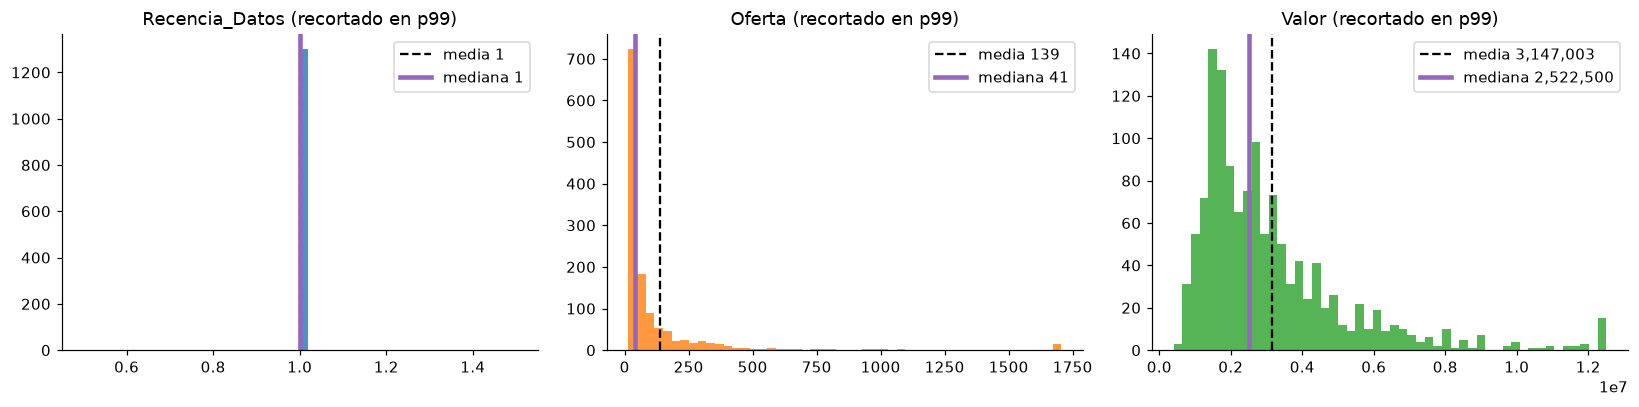

In [19]:
import matplotlib.pyplot as plt

# Si no tienes la variable PALETA definida previamente en tu código, define una aquí:
PALETA = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd"] 

fig, ejes = plt.subplots(1, 3, figsize=(15, 3.8))

# Reemplazamos las columnas de RFM por nuestras variables O.V.C.
columnas = ["Recencia_Datos", "Oferta", "Valor"]

for eje, col, color in zip(ejes, columnas, PALETA):
    # Recortamos en el percentil 99 para que los barrios extremos no aplasten el gráfico
    x = perfil[col].clip(upper=perfil[col].quantile(.99))
    
    eje.hist(x, bins=50, color=color, alpha=.8)
    
    eje.axvline(perfil[col].mean(), color="black", ls="--", label=f"media {perfil[col].mean():,.0f}")
    # Usamos un color diferente para la mediana (el 5to color de la paleta)
    eje.axvline(perfil[col].median(), color=PALETA[4], lw=3, label=f"mediana {perfil[col].median():,.0f}")
    
    eje.set_title(f"{col} (recortado en p99)")
    eje.legend()

plt.tight_layout()
plt.show()

In [20]:
# Concentración: ¿Qué porcentaje del mercado dominan los barrios principales?
orden = perfil["Oferta"].sort_values(ascending=False)
top20 = orden.head(int(len(orden) * .2)).sum() / orden.sum()

print(f"El 20 % de los barrios con mayor tamaño de mercado concentra el {top20:.1%} de toda la oferta (avisos).")

# Concentración por ciudad: ¿Cuáles ciudades dominan la oferta total en el dataset original?
# (Usamos 'df' aquí porque 'perfil' no tiene la columna de ciudad)
print("\nTop 5 ciudades con mayor concentración de la oferta:")
print(df.groupby("ciudad")["avisos"].sum().sort_values(ascending=False).head(5).div(df["avisos"].sum()).round(3))

El 20 % de los barrios con mayor tamaño de mercado concentra el 74.9% de toda la oferta (avisos).

Top 5 ciudades con mayor concentración de la oferta:
ciudad
Medellín        0.554
Bogotá          0.249
Rionegro        0.053
Cali            0.045
Barranquilla    0.031
Name: avisos, dtype: float64


# Etapa 3 · Entrenamiento → escena 4

| **Variable** | **Qué es** | **Para qué** |
|---|---|---|
| `VARIABLES` | `["Recencia_Datos", "Oferta", "Valor"]` | Columnas base del perfil que entran al modelo. |
| `X_crudo` | Matriz NumPy de n × 3 | Los valores originales sin transformar. |
| `X_log` | `log1p(X_crudo) = ln(1 + x)` | Comprimir los extremos; el +1 evita el error de ln(0) cuando la recencia es 0. |
| `escalador` | `StandardScaler` ajustado | Guarda la media (μ) y desviación (σ) de cada columna; se reutiliza para nuevos barrios. |
| `X` | Matriz final estandarizada | Media 0 y desviación 1 en cada variable: esta es la matriz que verá K-Means. |

In [22]:
from sklearn.preprocessing import StandardScaler
# 3.1 K-Means mide distancias: la escala importa

# 1. Definimos las variables de nuestro modelo O.V.C.
VARIABLES = ["Recencia_Datos", "Oferta", "Valor"]

# 2. Extraemos los datos crudos
X_crudo = perfil[VARIABLES].to_numpy(dtype=float)

# 3. Aplicamos logaritmo para comprimir los extremos (barrios con valores muy atípicos)
X_log = np.log1p(X_crudo)

# 4. Estandarizamos para que todas las variables pesen lo mismo
escalador = StandardScaler().fit(X_log)
X = escalador.transform(X_log)

# 5. Comparamos los rangos para verificar el impacto de la transformación
pd.DataFrame({
    "rango sin transformar": X_crudo.max(axis=0) - X_crudo.min(axis=0),
    "rango con log": X_log.max(axis=0) - X_log.min(axis=0),
    "media escalada": X.mean(axis=0), 
    "desviación escalada": X.std(axis=0)
}, index=VARIABLES).round(2)

,rango sin transformar,rango con log,media escalada,desviación escalada
Recencia_Datos,0.0,0.00,0.0,0.0
Oferta,8575.5,6.29,0.0,1.0
Valor,20100000.0,3.94,-0.0,1.0


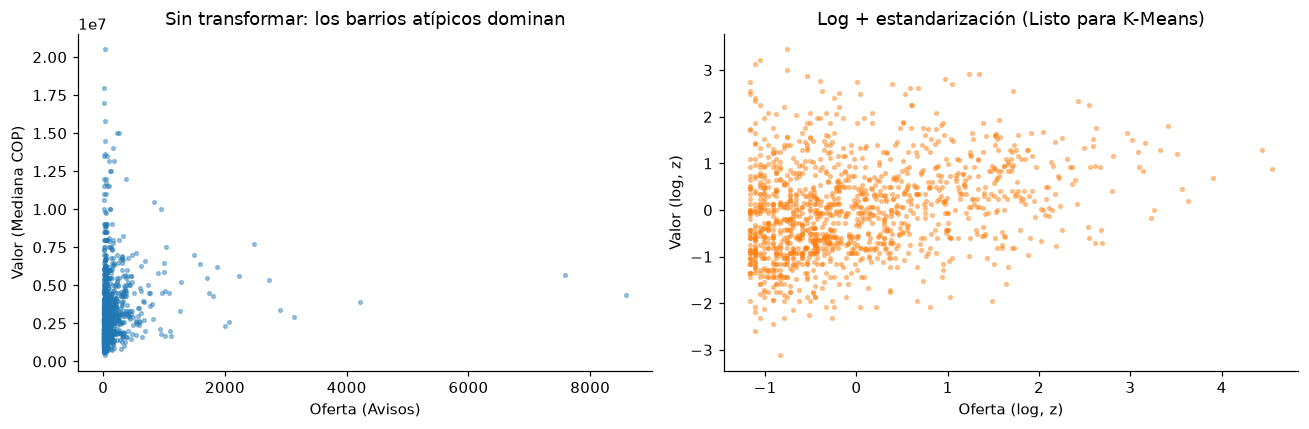

In [23]:
import matplotlib.pyplot as plt

# Asumiendo que PALETA ya está definida, ej: PALETA = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd"]

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))

# Gráfico 1: Datos originales (X_crudo)
# El índice 1 corresponde a "Oferta", el índice 2 corresponde a "Valor"
ejes[0].scatter(X_crudo[:, 1], X_crudo[:, 2], s=6, alpha=.4, color=PALETA[0])
ejes[0].set_xlabel("Oferta (Avisos)")
ejes[0].set_ylabel("Valor (Mediana COP)")
ejes[0].set_title("Sin transformar: los barrios atípicos dominan")

# Gráfico 2: Datos transformados (X)
ejes[1].scatter(X[:, 1], X[:, 2], s=6, alpha=.4, color=PALETA[1])
ejes[1].set_xlabel("Oferta (log, z)")
ejes[1].set_ylabel("Valor (log, z)")
ejes[1].set_title("Log + estandarización (Listo para K-Means)")

plt.tight_layout()
plt.show()

| **Variable** | **Qué es** | **Para qué** |
|---|---|---|
| `modelos` | Diccionario k → modelo KMeans entrenado | Reutilizar cada modelo sin tener que reentrenar. |
| `km.labels_` | Segmento asignado a cada **barrio** (0 … k − 1) | Calcular métricas y perfiles del clúster. |
| `km.inertia_` | Inercia del modelo | Graficar el método del codo. |
| `km.cluster_centers_` | Coordenadas de los centroides (en escala z) | Describir y nombrar el perfil de los segmentos de barrios. |
| `n_clusters, n_init, random_state` | Hiperparámetros de K-Means | k grupos · 10 inicios distintos para quedarse con el mejor · reproducibilidad. |
| `metricas_k` | Tabla de métricas por cada k | Ayudar a elegir el k (número de clústeres) óptimo. |
| `grupo más pequeño` | Tamaño del segmento con menos **barrios** | Evaluar el impacto operativo: ¿tiene sentido comercial gestionar una campaña para un clúster con tan pocos barrios? |

In [24]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

# Definimos una semilla para que el resultado sea reproducible
SEMILLA = 42 

filas = []
modelos = {}

# Probamos dividiendo la ciudad desde 2 hasta 10 grupos de barrios
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(X)
    modelos[k] = km
    
    filas.append({
        "k": k, 
        "inercia": km.inertia_,
        "silueta": silhouette_score(X, km.labels_),
        "Davies-Bouldin": davies_bouldin_score(X, km.labels_),
        "Calinski-Harabasz": calinski_harabasz_score(X, km.labels_),
        "grupo más pequeño": np.bincount(km.labels_).min()
    })

metricas_k = pd.DataFrame(filas).set_index("k")

# Mostramos la tabla redondeada a 3 decimales
metricas_k.round(3)

,inercia,silueta,Davies-Bouldin,Calinski-Harabasz,grupo más pequeño
k,,,,,
2,1478.209,0.411,1.012,985.033,510
3,967.977,0.399,0.876,1093.380,301
4,774.252,0.357,0.917,1018.691,149
5,614.662,0.364,0.858,1045.712,142
6,533.745,0.358,0.872,1001.935,117
7,469.093,0.337,0.891,978.933,122
8,405.232,0.365,0.807,999.661,38
9,352.560,0.355,0.811,1028.705,38
10,320.568,0.349,0.832,1019.188,38


# Etapa 4 · Análisis y métricas → escena 5

# ¿Cuántos perfiles de barrios existen de verdad?
La evaluación matemática de los clústeres funciona exactamente igual para clientes que para barrios. Lo que buscamos es el número ideal de grupos ($k$) donde los barrios sean muy similares entre sí, pero muy distintos a los de otros grupos.
* Inercia (Método del codo): Buscamos el punto donde la curva "se dobla" y deja de bajar drásticamente al añadir más grupos.
* Silueta: $s = (b - a) \div \max(a, b)$ → Cerca de 1 indica que un barrio está bien agrupado; cerca de 0 indica que el barrio está en la frontera entre dos perfiles; si es negativa, el algoritmo lo asignó al grupo equivocado.
* Davies-Bouldin: Más bajo es mejor (indica perfiles de barrios bien separados).
* Calinski-Harabasz: Más alto es mejor (indica grupos de barrios densos y bien definidos).

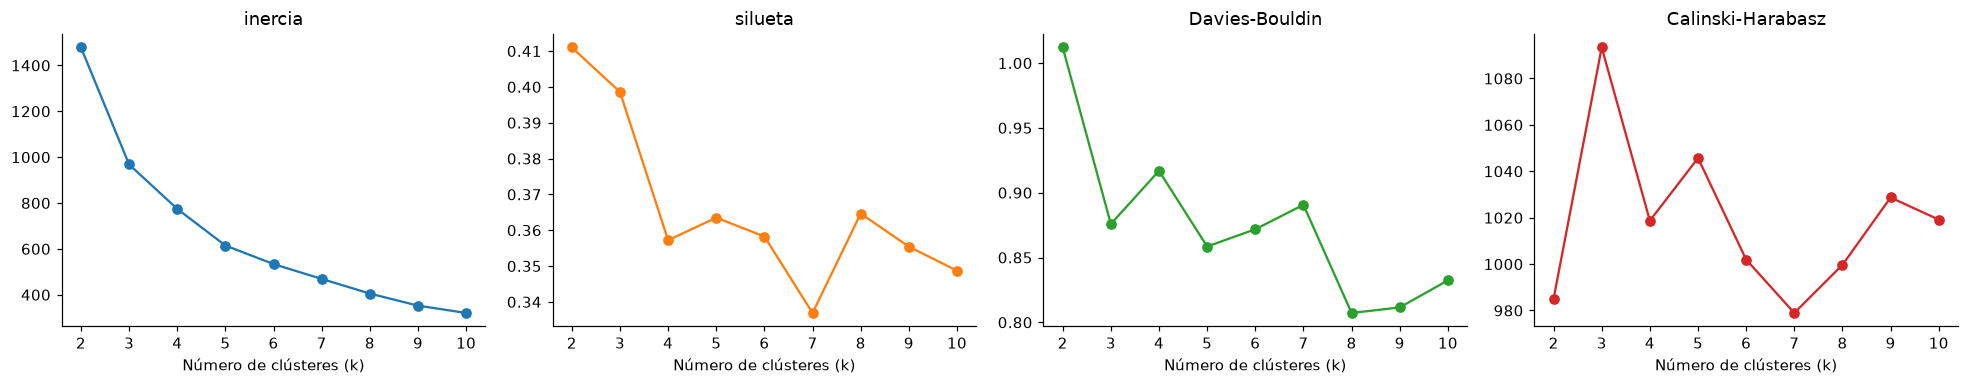

In [25]:
import matplotlib.pyplot as plt

# 4.1 Graficar las métricas para decidir el 'k' óptimo
# (Asume que PALETA = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd"] ya está definida)

fig, ejes = plt.subplots(1, 4, figsize=(18, 3.6))

# Las 4 métricas que calculamos en la escena anterior
metricas = ["inercia", "silueta", "Davies-Bouldin", "Calinski-Harabasz"]

for eje, col, color in zip(ejes, metricas, PALETA):
    # Graficamos k en el eje X, y el valor de la métrica en el eje Y
    eje.plot(metricas_k.index, metricas_k[col], "o-", color=color)
    eje.set_title(col)
    eje.set_xlabel("Número de clústeres (k)")

plt.tight_layout()
plt.show()

### 🔹 Variables del bloque

| **Variable** | **Qué es** | **Para qué** |
|---|---|---|
| `K_ELEGIDO` | El k decidido: métricas + negocio | Parámetro central; cámbialo en el reto. |
| `modelo` | El `KMeans` con k = 4 | El modelo final. |
| `rfm["segmento"]` | Número de segmento por cliente | ⚠️ El número (0, 1, 2, 3) **no tiene significado**: el orden es arbitrario; el nombre sale del perfil. |

In [26]:
# Elige 'k' mirando los gráficos de la escena anterior Y tu capacidad de negocio 
# (¿puedes diseñar y gestionar 3, 4 o 5 campañas inmobiliarias distintas?)

K_ELEGIDO = 4  # Cambia este número según lo que te hayan dicho el Codo y la Silueta

# Seleccionamos el modelo que ya entrenamos previamente con ese 'k'
modelo = modelos[K_ELEGIDO]

# Asignamos la etiqueta del clúster a nuestra tabla maestra de barrios
perfil["segmento"] = modelo.labels_

print(f"Se dividió la ciudad en k = {K_ELEGIDO} grupos de barrios · Puntaje de Silueta: {metricas_k.loc[K_ELEGIDO, 'silueta']:.3f}")

# Damos un vistazo rápido para confirmar que la nueva columna se agregó correctamente
perfil.head()

Se dividió la ciudad en k = 4 grupos de barrios · Puntaje de Silueta: 0.357


,Recencia_Datos,Oferta,Valor,TasaParqueadero,segmento
barrio,,,,,
20 de Julio,1,33.000000,1.776250e+06,0.424242,1
20 de Julio Sector Ii,1,35.000000,1.300000e+06,0.514286,1
A S D,1,66.333333,1.711667e+06,0.643216,1
Abajo,1,27.000000,1.070000e+06,0.222222,1
Abraham Lincoln,1,15.000000,2.561470e+06,0.000000,3


In [27]:
# 4.2 Comparar escenarios: el impacto de escalar los datos y elegir bien la 'k'

# Entrenamos un modelo con los datos originales (sin logaritmo ni estandarización) 
# para demostrar el error de no transformar la matriz O.V.C.
sin_escalar = KMeans(n_clusters=K_ELEGIDO, n_init=10, random_state=SEMILLA).fit(X_crudo)

def resumen(nombre, etiquetas, espacio):
    tam = np.bincount(etiquetas)
    return {
        "escenario": nombre, 
        "grupos": len(tam), 
        "silueta": silhouette_score(espacio, etiquetas),
        "grupo más grande %": tam.max() / tam.sum() * 100, 
        "grupo más pequeño": tam.min()
    }

escenarios = pd.DataFrame([
    resumen("1 · k = 2 (Demasiado general)", modelos[2].labels_, X),
    resumen("2 · k = 10 (Demasiado fragmentado)", modelos[10].labels_, X),
    resumen(f"3 · k elegido = {K_ELEGIDO} (Equilibrado)", modelo.labels_, X),
    resumen(f"4 · k = {K_ELEGIDO} sin transformar datos (El Valor domina)", sin_escalar.labels_, X_crudo),
]).set_index("escenario")

escenarios.round(3)

,grupos,silueta,grupo más grande %,grupo más pequeño
escenario,,,,
1 · k = 2 (Demasiado general),2,0.411,60.769,510
2 · k = 10 (Demasiado fragmentado),10,0.349,19.846,38
3 · k elegido = 4 (Equilibrado),4,0.357,35.769,149
4 · k = 4 sin transformar datos (El Valor domina),4,0.587,47.462,32


| **Variable** | **Qué es** | **Para qué** |
|---|---|---|
| `resumen_grupos` | Tabla por segmento con medianas de Recencia, Oferta y Valor | Describir cada grupo; la mediana resiste a los extremos (reemplaza a `perfil` del retail para no borrar tu tabla maestra). |
| `% barrios`, `% mercado` | Peso de cada segmento | Ver cuánto representa cada clúster en cantidad de zonas y en volumen de oferta inmobiliaria. |
| `centroides` | DataFrame con los centroides en z | La huella del segmento: > 0 está por encima del promedio de la ciudad, < 0 por debajo. |
| `nombrar(c)` | Regla de nombres | Clasificar comercialmente: ej. `datos_frescos` si Recencia_Datos en z < 0.3; `atractivo` = promedio de Oferta y Valor. |
| `nombres`, `perfil["nombre"]` | Nombre de cada segmento y de cada barrio | Traducir los números de los clústeres (0, 1, 2...) a lenguaje de negocio (ej. "Zonas Premium"). |

In [28]:
# 4.3 Nombrar y describir los clústeres
# Usamos "resumen_grupos" como nombre de esta tabla para no sobrescribir tu dataframe "perfil"
resumen_grupos = perfil.groupby("segmento").agg(
    barrios=("Valor", "size"), 
    Recencia_mediana=("Recencia_Datos", "median"),
    Oferta_mediana=("Oferta", "median"), 
    Valor_mediano=("Valor", "median"), 
    Oferta_total=("Oferta", "sum")
)

# Calculamos el peso del clúster
resumen_grupos["% barrios"] = resumen_grupos["barrios"] / resumen_grupos["barrios"].sum() * 100
resumen_grupos["% mercado"] = resumen_grupos["Oferta_total"] / resumen_grupos["Oferta_total"].sum() * 100

# Nombres a partir de los centroides (en unidades estandarizadas z)
# Recencia baja (z < 0.3) = el barrio tiene avisos frescos o recientes
centroides = pd.DataFrame(modelo.cluster_centers_, columns=VARIABLES)

# Regla inmobiliaria: evaluamos si los datos son frescos y combinamos Oferta y Valor para medir su 'atractivo'
def nombrar(c):
    datos_frescos = c["Recencia_Datos"] < 0.3
    atractivo = (c["Oferta"] + c["Valor"]) / 2
    
    if datos_frescos and atractivo > 0.8: return "Zonas Premium (Alto Costo y Oferta)"
    if datos_frescos and atractivo > 0:   return "Zonas Dinámicas (Mercado Activo)"
    if datos_frescos:                     return "Zonas Económicas o Populares"
    if atractivo > 0:                     return "Zonas Costosas (Datos Desactualizados)"
    return "Zonas Inactivas o Periféricas"

nombres = centroides.apply(nombrar, axis=1)
# Si por coincidencia matemática dos grupos caen en la misma regla, les agregamos un número para diferenciarlos
nombres = nombres.where(~nombres.duplicated(keep=False), nombres + " " + nombres.index.astype(str))

# Asignamos los nombres al resumen y a tu tabla maestra de barrios
resumen_grupos["nombre"] = nombres
perfil["nombre"] = perfil["segmento"].map(nombres)

# Mostramos el resultado ordenado por el tamaño del mercado que controlan
resumen_grupos.sort_values("% mercado", ascending=False).round(1)

,barrios,Recencia_mediana,Oferta_mediana,Valor_mediano,Oferta_total,% barrios,% mercado,nombre
segmento,,,,,,,,
2,268,1.0,300.5,3500000.0,135575.3,20.6,75.0,Zonas Premium (Alto Costo y Oferta)
3,418,1.0,34.5,2800000.0,18378.6,32.2,10.2,Zonas Económicas o Populares 3
1,465,1.0,29.0,1500000.0,18318.7,35.8,10.1,Zonas Económicas o Populares 1
0,149,1.0,40.0,6500000.0,8610.0,11.5,4.8,Zonas Dinámicas (Mercado Activo)


# Lectura de resultados (Análisis de tu tabla O.V.C.)
* Concentración del mercado: El segmento de "Zonas Premium" representa el verdadero núcleo del negocio: agrupa solo al 20.6% de los barrios, pero concentra el 75.0% de toda la oferta de inmuebles en arriendo. Tienen el volumen más alto con una mediana de 300.5 avisos por barrio.
* Zonas Exclusivas (Bajo volumen, Alto precio): El segmento 0 ("Zonas Dinámicas") representa los barrios más costosos de la ciudad, con una mediana de arriendo de $6.500.000 COP. Sin embargo, son un nicho pequeño, abarcando solo el 4.8% del mercado total.
* La base de la pirámide (Económicas/Populares): Los segmentos 1 y 3 conforman la gran mayoría territorial de la ciudad (combinados son el 68% de los barrios). Tienen precios medianos más accesibles ($1.5M y $2.8M), pero un volumen de oferta muy bajo por barrio (apenas ~29 a 34 avisos), sumando en conjunto solo el 20.3% del mercado total.
* Recencia constante: Todos los segmentos tienen una recencia mediana de 1.0 día, lo que indica que tu base de datos está perfectamente actualizada en todas las zonas de la ciudad.

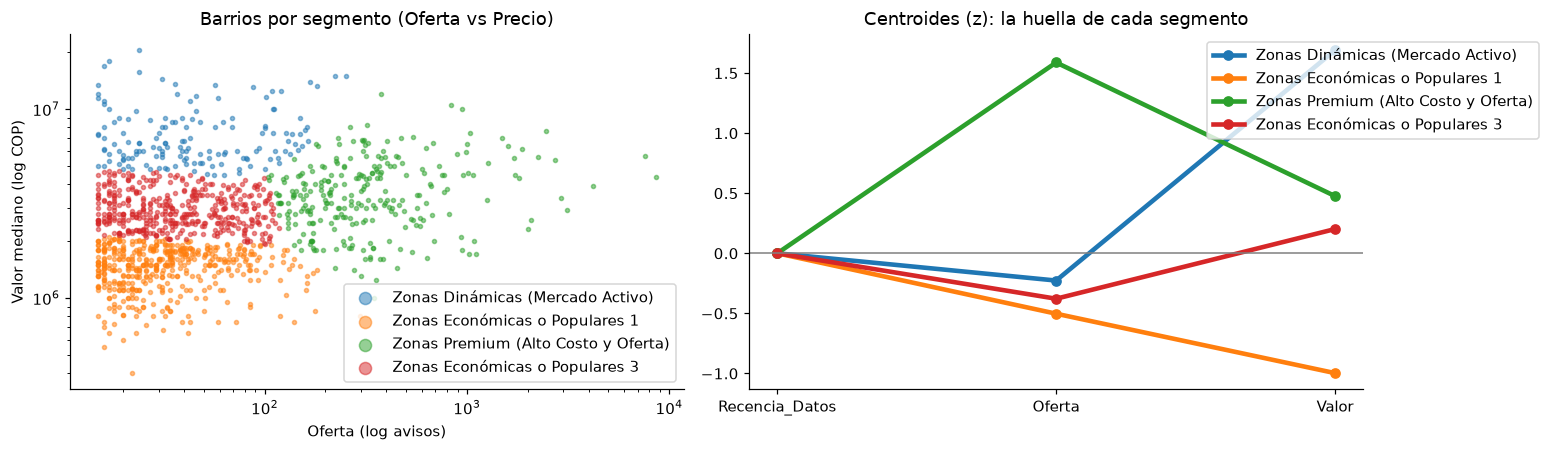

In [29]:
import matplotlib.pyplot as plt

# Asumimos que PALETA y 'nombres' ya están definidos en las celdas anteriores
fig, ejes = plt.subplots(1, 2, figsize=(14, 4.2))

# 1. Gráfico de dispersión: Oferta vs Valor
for s, g in perfil.groupby("segmento"):
    ejes[0].scatter(g["Oferta"], g["Valor"], s=7, alpha=.5, color=PALETA[s], label=nombres[s])

# Usamos escala logarítmica para evitar que los valores muy altos aplasten el gráfico
ejes[0].set_yscale("log")
ejes[0].set_xscale("log") 
ejes[0].set_xlabel("Oferta (log avisos)")
ejes[0].set_ylabel("Valor mediano (log COP)")
ejes[0].set_title("Barrios por segmento (Oferta vs Precio)")
ejes[0].legend(markerscale=3)

# 2. Gráfico de centroides (Huella z)
for s in centroides.index:
    ejes[1].plot(VARIABLES, centroides.loc[s], "o-", lw=3, color=PALETA[s], label=nombres[s])

ejes[1].axhline(0, color="gray", lw=1)
ejes[1].set_title("Centroides (z): la huella de cada segmento")
# Movemos la leyenda un poco si estorba visualmente
ejes[1].legend(loc='upper right', bbox_to_anchor=(1.3, 1))

plt.tight_layout()
plt.show()

In [32]:
import datetime
from clases_po import Reportes

# 1. Construir el texto del resumen dinámicamente con las variables del entorno
resumen_texto = f"""==================================================
RESUMEN AUTOMÁTICO DE EJECUCIÓN - SEGMENTACIÓN O.V.C.
==================================================
Fecha de ejecución: {datetime.datetime.now().strftime('%Y-%m-%d %H:%M:%S')}

1. PREGUNTA DE NEGOCIO
¿Qué segmentos o perfiles de barrios existen en la ciudad según su nivel de precios y su volumen de oferta, para diseñar campañas de marketing inmobiliario personalizadas?

2. DATASET Y PREPROCESAMIENTO
- Origen de datos: precios_arriendo_barrios.csv
- Total de barrios segmentados: {len(perfil)}
- Preprocesamiento: 
  * Eliminación de valores nulos, avisos <= 0 y precios <= 0.
  * Validación lógica de rangos (p25 <= p75).
- Transformación: Logaritmo (log1p) para control de valores extremos + Estandarización (StandardScaler) en z.

3. CONFIGURACIÓN DEL EXPERIMENTO
- Tipo de Aprendizaje: No Supervisado
- Algoritmo: K-Means
- Variables de entrada: Recencia_Datos, Oferta (avisos), Valor (mediana)
- Parámetros: k={K_ELEGIDO}, n_init=10, random_state={SEMILLA}

4. MÉTRICAS DEL MODELO FINAL (k={K_ELEGIDO})
- Inercia: {modelo.inertia_:.2f}
- Coeficiente de Silueta: {metricas_k.loc[K_ELEGIDO, 'silueta']:.3f}
- Índice Davies-Bouldin: {metricas_k.loc[K_ELEGIDO, 'Davies-Bouldin']:.3f}
- Índice Calinski-Harabasz: {metricas_k.loc[K_ELEGIDO, 'Calinski-Harabasz']:.3f}
==================================================
"""

ruta = "reportes/Reporte Segmentacion.txt"

# 4. Guardar el archivo usando las funciones nativas de Python
with open(ruta, "w", encoding="utf-8") as archivo:
    archivo.write(resumen_texto)

print(f"Reporte guardado en: {ruta}")

Reporte guardado en: reportes/Reporte Segmentacion.txt
